<h1> Experiment reflection against photon momentum </h1>

In [1]:
#General imports
resol = 300
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "axes.linewidth": 0.7,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.direction": "in",
    "ytick.direction": "in",

    # Lines / markers
    "lines.linewidth": 1.0,
    "lines.markersize": 4,

})

import sys
import numpy as np
from pathlib import Path
pi = np.pi

project_root = Path().resolve().parents[1]
sys.path.append(str(project_root))

#Local imports
from waveguide_model.scripts_experiments.reflection_vs_frequency import run_reflection_vs_frequency
from waveguide_model.src.bare_param import get_bare_param_n


<h2> Execute the experiment </h2>

To assess the impact of the momentum cutoff window, we run the experiment several times. Each experiment corresponds to a given cutoff window $[\Lambda_{
m IR}, \Lambda_{
m UV}]$

In [2]:
#Parameters of the simulation
param_photon_bis = {'sigma_p': 0.05*np.pi, 'x_0': -25}  # p_0 will be varied in this experiment

omega_A = 10*np.pi
gamma_A = np.pi
L = 100
param_cavity_physical = {'omega_A': omega_A, 'gamma_A': gamma_A, 'L': L}

param_time_evol = {'T': 50, 'dt': 0.01}

#Define an array of central momenta around the TLS resonance
nb_p0 = 21
p0_tab = np.linspace(omega_A - gamma_A/2,
                     omega_A + gamma_A/2, nb_p0)

#Assess the reflection curve for different momentum cutoff windows
cutoff_windows = [
    (0, 20*pi),
    (0, 14*pi),
    (8*pi, 14*pi),
    (9*pi, 11*pi),
]


Run the experiment for each momentum cutoff window

In [5]:
correction = True
n = 1 if correction else -1

for i in range(len(cutoff_windows)):
    index_experiment = i+1
    print("Running cutoff window number ", index_experiment, " out of ", len(cutoff_windows))
    cutoffs = {'ir_cutoff': cutoff_windows[i][0], 'uv_cutoff': cutoff_windows[i][1]}
    omega_0, gamma_0 = get_bare_param_n(omega_A, gamma_A, cutoffs['ir_cutoff'], cutoffs['uv_cutoff'], n=n)
    param_cavity = {'omega_0': omega_0, 'gamma_0': gamma_0, 'L': L}
    #Run the experiment

    p0_values, final_reflection_tab = run_reflection_vs_frequency(param_photon_bis, param_cavity, param_time_evol, p0_tab, cutoffs,
                                                                  index_experiment=index_experiment, correction=correction, progress=True)


Running cutoff window number  1  out of  4


100%|██████████| 21/21 [00:14<00:00,  1.41it/s]


Running cutoff window number  2  out of  4


100%|██████████| 21/21 [00:12<00:00,  1.73it/s]


Running cutoff window number  3  out of  4


100%|██████████| 21/21 [00:08<00:00,  2.55it/s]


Running cutoff window number  4  out of  4


100%|██████████| 21/21 [00:06<00:00,  3.34it/s]


<h2> Plot the results </h2>

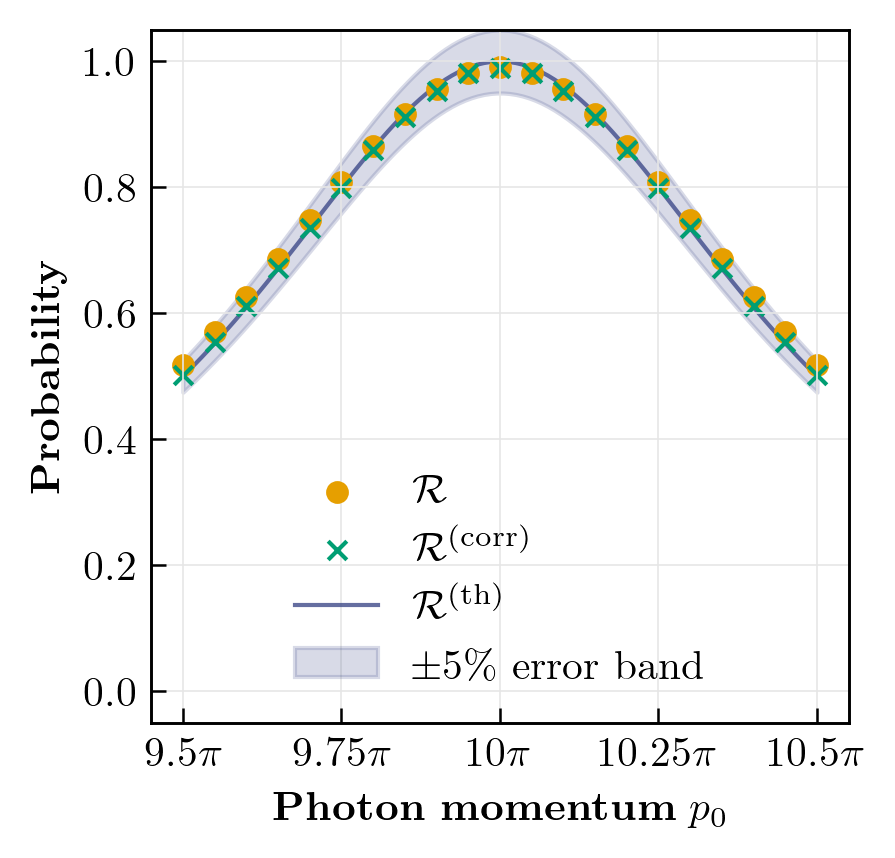

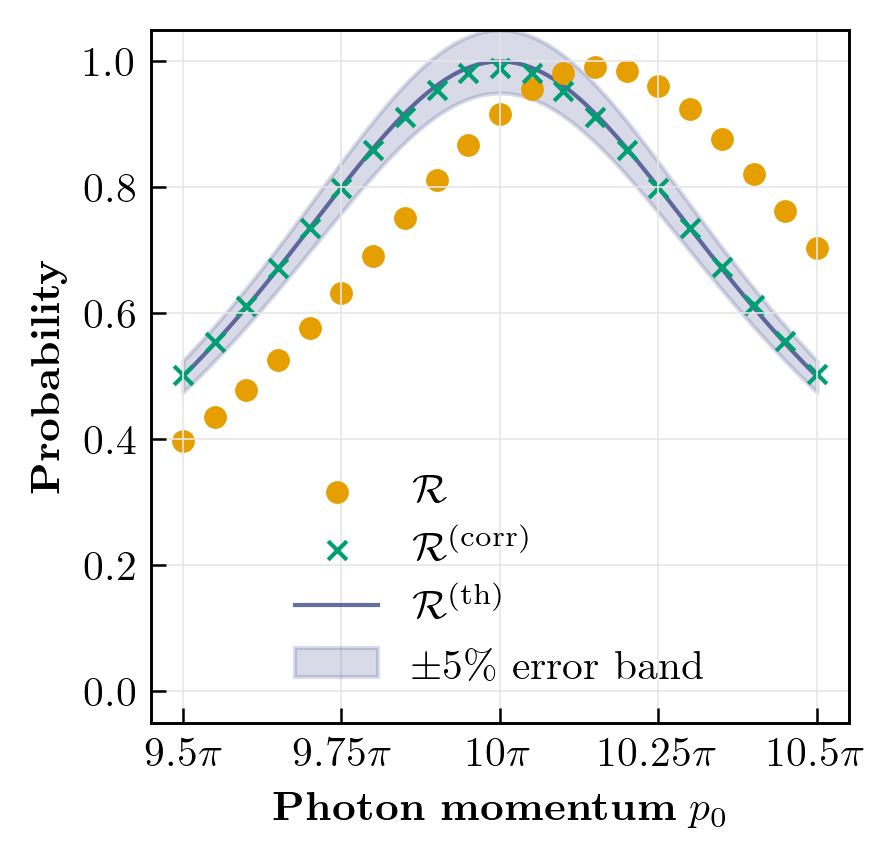

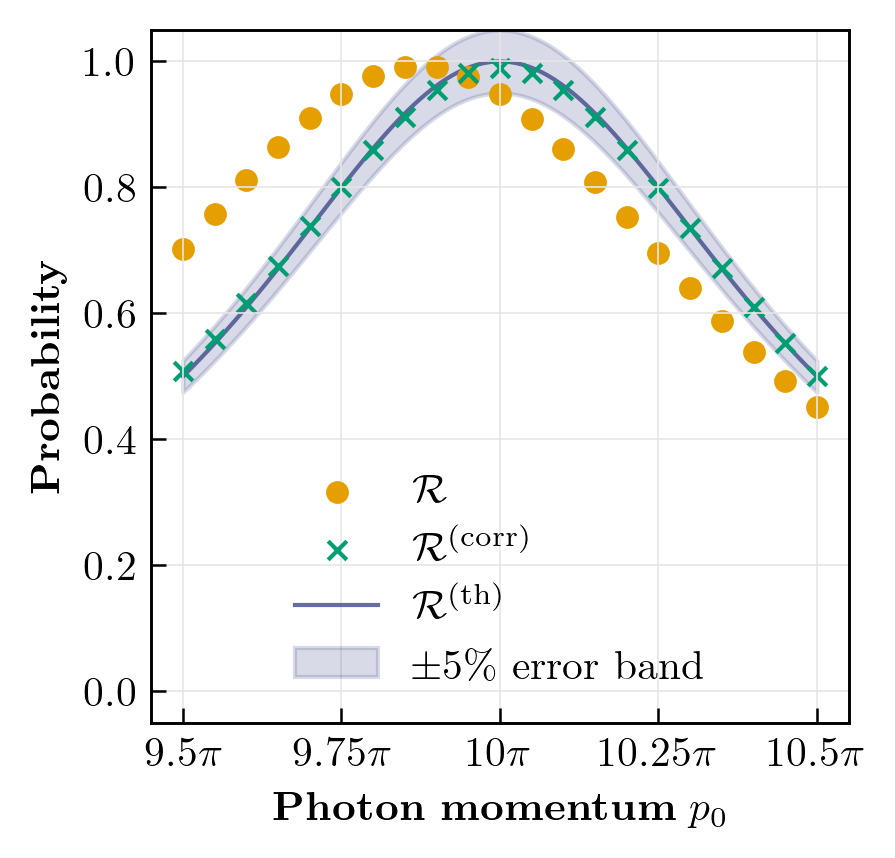

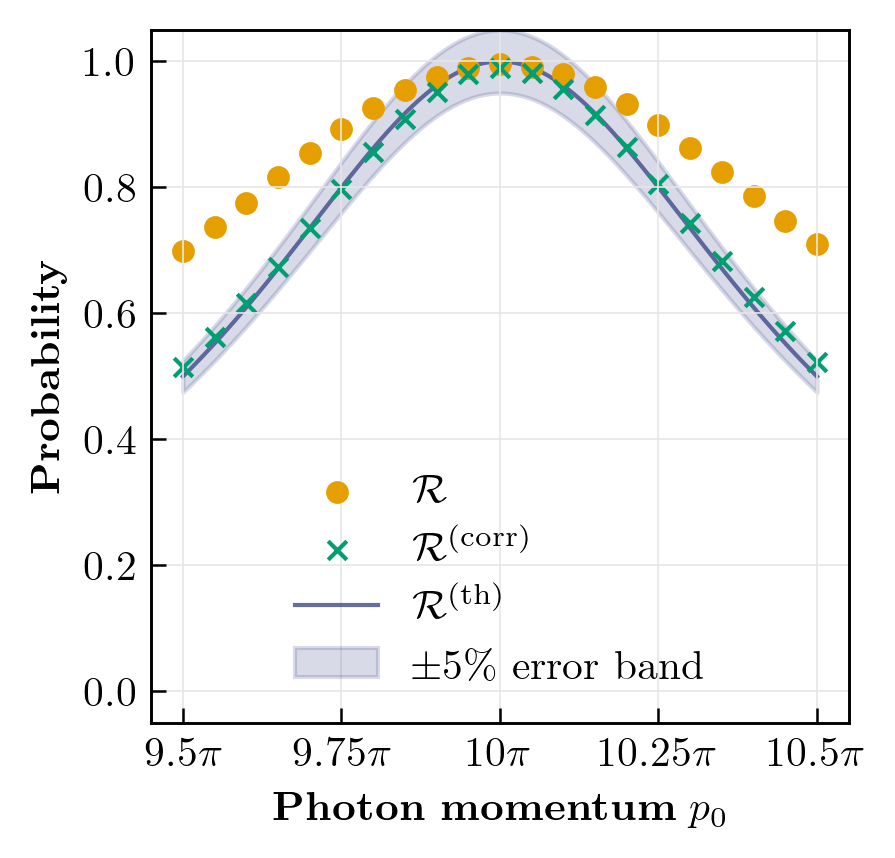

In [ ]:
correction = True
show_fig = False

for index_experiment in [1,2,3,4]:

    ### Load the data
    ir_cutoff = cutoff_windows[index_experiment-1][0]
    uv_cutoff = cutoff_windows[index_experiment-1][1]

    data_file = f"../results/csv_files/reflection_vs_frequency/reflection_vs_frequency_{index_experiment}_uncorrected.csv"
    df = pd.read_csv(data_file)
    photon_momentum_tab_uncorrected = df['photon_momentum_tab'].to_numpy()
    final_reflection_tab_uncorrected = df['final_reflection_tab'].to_numpy()

    if correction:
        data_file = f"../results/csv_files/reflection_vs_frequency/reflection_vs_frequency_{index_experiment}_corrected.csv"
        df = pd.read_csv(data_file)
        photon_momentum_tab_corrected = df['photon_momentum_tab'].to_numpy()
        final_reflection_tab_corrected = df['final_reflection_tab'].to_numpy()

    ###Generate the theoretical curve

    p0_tab_theory = np.linspace(omega_A - gamma_A/2, omega_A + gamma_A/2, 100)
    #Bare prediction
    R_theory = 1 / (1 + ((p0_tab_theory - omega_A)/ (gamma_A/2))**2)


    ### Création de la figure

    fig, ax = plt.subplots(figsize=(3, 3), dpi=300)

    color_bare = "#3E4A89"
    color_data = "#E69F00"
    color_data_corrected = "#009E73"

    #data points uncorrected
    ax.scatter(photon_momentum_tab_uncorrected, final_reflection_tab_uncorrected, label=r'$\mathcal{R}$', color=color_data, s=20)
    if correction:
        #data points corrected
        ax.scatter(photon_momentum_tab_corrected, final_reflection_tab_corrected, label=r'$\mathcal{R}^{(\rm corr)}$', color=color_data_corrected, s=20, marker="x")

    #theoretical curve
    ax.plot(p0_tab_theory, R_theory, color=color_bare, alpha=0.8, zorder = -1, label=r'$\mathcal{R}^{(\rm th)}$')
    if correction:
        #Display a 5% error band around the theoretical curve
        ax.fill_between(p0_tab_theory, 0.95*R_theory, 1.05*R_theory, color=color_bare, alpha=0.2, zorder = -2, label=r'$\pm 5\%$ error band')

    # Labels, limites et grille
    ax.set_xlabel(r'\textbf{Photon momentum} $p_0$', fontsize=10)
    ax.set_xticks([omega_A - gamma_A/2,
                omega_A - gamma_A/4,
                omega_A,
                omega_A + gamma_A/4,
                omega_A + gamma_A/2])

    ax.set_xticklabels([r"$9.5\pi$",r"$9.75\pi$",r"$10\pi$",r"$10.25\pi$",r"$10.5\pi$"])

    ax.set_ylabel(r'\textbf{Probability}', fontsize=10)
    ax.set_ylim(-0.05, 1.05)
    ax.grid(color='0.9', linestyle='-', linewidth=0.4)

    # Légende sobre
    ax.legend(prop={'size': 10}, loc="lower center", frameon=False)

    #font size
    for item in [ax.xaxis.label, ax.yaxis.label]:
        item.set_fontsize(10)

    for item in (ax.get_xticklabels() + ax.get_yticklabels()):
        item.set_fontsize(10)

    if correction:
        plt.savefig("../results/fig/reflection_multi_cutoff_experiment_"+str(index_experiment)+"_corrected.pdf", bbox_inches="tight")
    else:
        plt.savefig("../results/fig/reflection_multi_cutoff_experiment_"+str(index_experiment)+"_uncorrected.pdf", bbox_inches="tight")

    if show_fig:
        plt.show()
